# Notebook 03 - Logistic Regression: will the student pass?
**Question:** will a student score **70 or more** (pass = 1) or not (pass = 0)? The answer is a **class**, so this is **classification**.

Logistic regression keeps the straight-line formula, then transform it into a probability with the **sigmoid**:
$$z = b_0 + b_1 x_1 + \dots + b_k x_k \qquad P(\text{pass}) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

**The optimization objective** is no longer squared error. It is the **log-loss** (cross-entropy), averaged over students:
$$\text{LogLoss}(b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \ln p_i + (1-y_i)\ln(1-p_i)\Big]$$
Minimizing it is the same as choosing the $b$ values that make the observed passes and fails **most likely** (maximum likelihood).

| Step | What |
|---|---|
| 1 | Load data, look at the classes, baseline |
| 2 | Why not linear regression on 0/1? |
| 3 | The sigmoid with one feature |
| 4 | **The objective:** log-loss, why not accuracy, gradient descent with and without scaling |
| 5-6 | Train on all features; probabilities |
| 7 | Confusion matrix, accuracy, precision, recall |
| 8 | Choosing a threshold for an early-warning system |
| 9 | ROC curve and AUC |
| 10 | Coefficients as odds ratios |
| 11 | Logistic vs "linear regression, then cut at 70" |
| 12 | Predict new students |

## Step 1 - Load the data and look at the classes

In [278]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
import joblib

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "make_data.py").exists())
sys.path.append(str(ROOT))
from src.quiz import check, summary
DATA = ROOT / "data"
assert (DATA / "train_scaled.csv").exists(), "Run notebook 01 first!"
plt.rcParams["figure.dpi"] = 110

prep = joblib.load(DATA / "preprocessing.joblib")
FEATURES, scaler = prep["features"], prep["scaler"]
missing = sorted(set(range(1, 10)) - set(prep["patches"]))
if missing:
    print(f"⚠️  Notebook 01 was saved WITHOUT patches {missing}. Everything below still runs,")
    print("    but your numbers will differ from the text. Finish notebook 01 first!\n")
TARGET = "passed"

train = pd.read_csv(DATA / "train_scaled.csv")          # scaled (if Patch 9 was applied)
test = pd.read_csv(DATA / "test_scaled.csv")
train_raw = pd.read_csv(DATA / "train_processed.csv")   # unscaled copy, in real units
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(y_train.value_counts().rename({1: "pass (1)", 0: "fail (0)"}))
print(f"pass rate: {y_train.mean():.1%}")

passed
pass (1)    214
fail (0)    106
Name: count, dtype: int64
pass rate: 66.9%


In [279]:
baseline = np.ones(len(y_test), dtype=int)
print(f"Baseline 'everyone passes' accuracy: {accuracy_score(y_test, baseline):.3f}")
print(f"Failing students it finds: 0 of {(y_test == 0).sum()}")

Baseline 'everyone passes' accuracy: 0.675
Failing students it finds: 0 of 26


## Step 2 - Why not just use linear regression on 0/1?

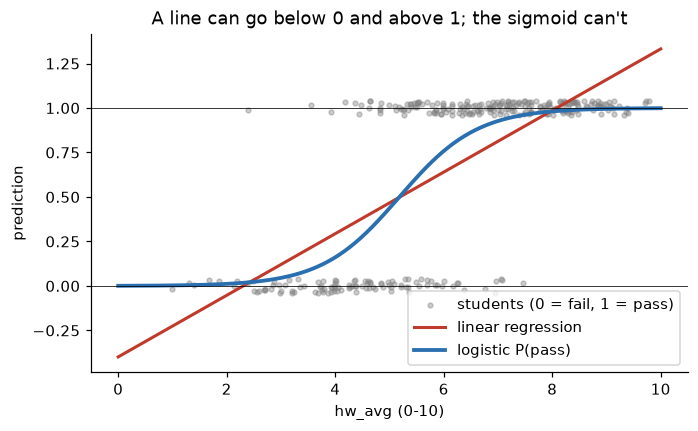

In [280]:
x1 = train_raw[["hw_avg"]]
line = LinearRegression().fit(x1, y_train)
logit1 = LogisticRegression().fit(x1, y_train)

grid = pd.DataFrame({"hw_avg": np.linspace(0, 10, 200)})
jitter = y_train + np.random.default_rng(0).uniform(-0.04, 0.04, len(y_train))
plt.figure(figsize=(7, 4))
plt.scatter(x1["hw_avg"], jitter, s=10, alpha=0.4, color="gray", label="students (0 = fail, 1 = pass)")
plt.plot(grid["hw_avg"], line.predict(grid), color="#c0392b", lw=2, label="linear regression")
plt.plot(grid["hw_avg"], logit1.predict_proba(grid)[:, 1], color="#2a6fb0", lw=2.5, label="logistic P(pass)")
plt.axhline(0, color="k", lw=0.5); plt.axhline(1, color="k", lw=0.5)
plt.xlabel("hw_avg (0-10)"); plt.ylabel("prediction"); plt.legend(loc="lower right")
plt.title("A line can go below 0 and above 1; the sigmoid can't")
plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

## Step 3 - The sigmoid with one feature

In [281]:
b0, b1 = logit1.intercept_[0], logit1.coef_[0, 0]
print(f"z = {b0:.2f} + {b1:.2f} x hw_avg")
for hw in [3, 4, 5, 6, 7, 8, 9]:
    z = b0 + b1 * hw
    print(f"hw_avg {hw}: z = {z:6.2f}  ->  P(pass) = {1 / (1 + np.exp(-z)):.2f}")
print(f"P(pass) = 0.5 where z = 0: hw_avg = {-b0 / b1:.2f}  (the decision boundary)")

z = -7.24 + 1.40 x hw_avg
hw_avg 3: z =  -3.05  ->  P(pass) = 0.05
hw_avg 4: z =  -1.65  ->  P(pass) = 0.16
hw_avg 5: z =  -0.26  ->  P(pass) = 0.44
hw_avg 6: z =   1.14  ->  P(pass) = 0.76
hw_avg 7: z =   2.54  ->  P(pass) = 0.93
hw_avg 8: z =   3.94  ->  P(pass) = 0.98
hw_avg 9: z =   5.33  ->  P(pass) = 1.00
P(pass) = 0.5 where z = 0: hw_avg = 5.18  (the decision boundary)


> ### Checkpoint L1
> What values can $\sigma(z) = 1/(1+e^{-z})$ take?
>
> **A)** any real number  
> **B)** only values between 0 and 1  
> **C)** values between -1 and 1  
> **D)** values between 0 and 100  


In [282]:
check("L1", 'B')   # <- replace ? with your answer

[L1] Correct!
  Why: sigma(z) is always strictly between 0 and 1, so it can be read as a probability.


## Step 4 - The objective: log-loss
### 4a. How much does one prediction cost?
For one student, log-loss is $-\ln(\text{probability the model gave to what really happened})$:
* the student passed ($y=1$): loss $= -\ln p$
* the student failed ($y=0$): loss $= -\ln(1-p)$

In [283]:
cases = [(1, 0.95), (1, 0.60), (1, 0.50), (1, 0.10), (1, 0.01), (0, 0.10), (0, 0.90)]
pd.DataFrame([{"actually passed?": y, "model's P(pass)": p,
               "log-loss": -np.log(p) if y == 1 else -np.log(1 - p)} for y, p in cases]).round(3)

,actually passed?,model's P(pass),log-loss
0,1,0.95,0.051
1,1,0.60,0.511
2,1,0.50,0.693
3,1,0.10,2.303
4,1,0.01,4.605
5,0,0.10,0.105
6,0,0.90,2.303


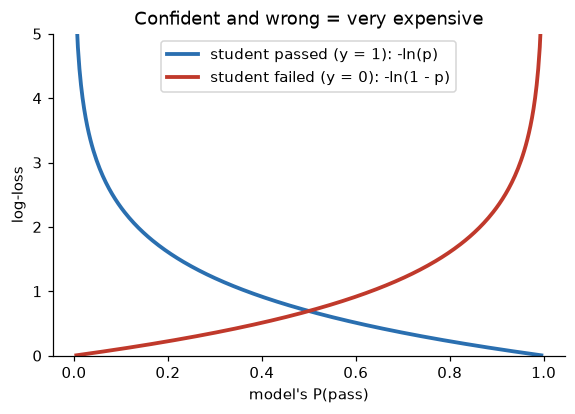

In [284]:
p = np.linspace(0.005, 0.995, 300)
plt.figure(figsize=(6, 3.8))
plt.plot(p, -np.log(p), color="#2a6fb0", lw=2.5, label="student passed (y = 1): -ln(p)")
plt.plot(p, -np.log(1 - p), color="#c0392b", lw=2.5, label="student failed (y = 0): -ln(1 - p)")
plt.xlabel("model's P(pass)"); plt.ylabel("log-loss"); plt.ylim(0, 5); plt.legend()
plt.title("Confident and wrong = very expensive")
plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

> ### Checkpoint L2
> A student **passed**. The model said **P(pass) = 0.8**. What is the log-loss for this student? (Use the calculator cell.)
>
> *Answer with a number (3 decimals).*


In [285]:
check("L2", '0.223')   # <- replace ? with your answer

[L2] Correct!
  Why: -ln(0.8) = 0.223. A confident, correct prediction costs little.


> ### Checkpoint L3
> Which single prediction has the **largest** log-loss?
>
> **A)** passed, model said P(pass) = 0.9  
> **B)** failed, model said P(pass) = 0.4  
> **C)** passed, model said P(pass) = 0.05  
> **D)** failed, model said P(pass) = 0.1  


In [286]:
check("L3", 'C')   # <- replace ? with your answer

[L3] Correct!
  Why: C gives the true class (pass) only 5%: -ln(0.05) = 3.0. A: 0.105, B: -ln(0.6) = 0.51, D: -ln(0.9) = 0.105. Confident and wrong is punished hardest.


### 4b. Why not just maximize accuracy?
Accuracy is what we report, so why not train on it? Take the one-feature model from Step 3, keep $b_0$ fixed, and slide $b_1$. Compare the two possible objectives.

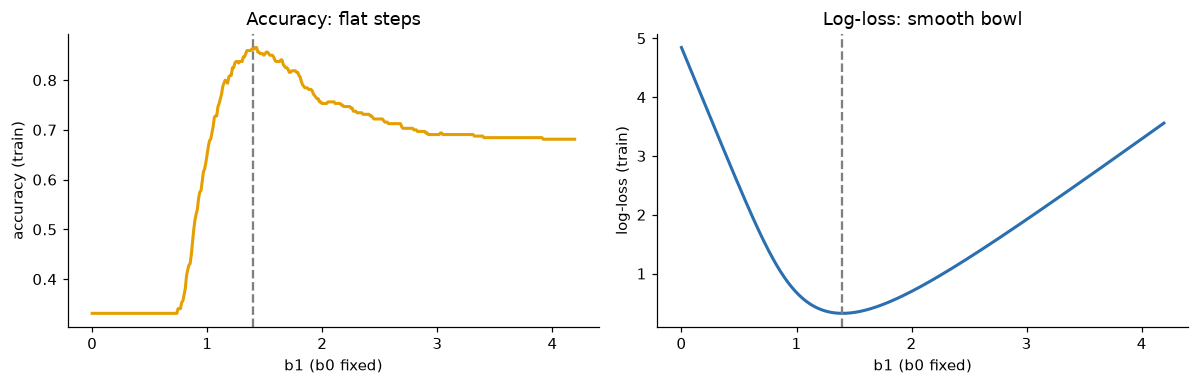

In [287]:
x_hw, y_tr = train_raw["hw_avg"].values, y_train.values
b1_values = np.linspace(0, 3 * b1, 400)
acc_curve, loss_curve = [], []
for s in b1_values:
    p_s = 1 / (1 + np.exp(-(b0 + s * x_hw)))
    acc_curve.append(np.mean((p_s >= 0.5) == y_tr))
    loss_curve.append(log_loss(y_tr, p_s))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(b1_values, acc_curve, color="#e69f00", lw=2); axes[0].set_title("Accuracy: flat steps")
axes[1].plot(b1_values, loss_curve, color="#2a6fb0", lw=2); axes[1].set_title("Log-loss: smooth bowl")
for ax, lab in zip(axes, ["accuracy (train)", "log-loss (train)"]):
    ax.axvline(b1, color="gray", ls="--"); ax.set_xlabel("b1 (b0 fixed)"); ax.set_ylabel(lab)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

> ### Checkpoint L6
> Why is logistic regression trained by minimizing **log-loss** instead of maximizing **accuracy**?
>
> **A)** Accuracy only changes when a prediction crosses the threshold, so it is flat almost everywhere with no slope to follow; log-loss is smooth and still rewards being more confident when right  
> **B)** Accuracy is harder to compute  
> **C)** Log-loss is always a bigger number  
> **D)** scikit-learn does not support accuracy  


In [288]:
check("L6", 'A')   # <- replace ? with your answer

[L6] Correct!
  Why: Accuracy only changes when a prediction crosses the threshold, so it is flat almost everywhere: no slope for gradient descent to follow. Log-loss is smooth and convex and still rewards becoming more confident in the right answer.


### 4c. Gradient descent on log-loss - with and without scaling (optional knowledge points)
The gradient of log-loss has a neat form: $\nabla = \frac{1}{n} X^\top (p - y)$ - "prediction minus truth, times the features."

We run gradient descent **twice** on the same features: once on the raw numbers, once standardized (Patch 9). For each, we try several learning rates and keep the best one, so the comparison is fair.

In [289]:
X_raw = train_raw[FEATURES].values.astype(float)
X_std = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)        # what Patch 9 does

def gd_logistic(X, y, lr, steps=300):
    X1 = np.c_[np.ones(len(X)), X]                       # column of 1s for the intercept b0
    w, losses = np.zeros(X1.shape[1]), []
    for _ in range(steps):
        p = 1 / (1 + np.exp(-np.clip(X1 @ w, -30, 30)))
        losses.append(log_loss(y, np.clip(p, 1e-12, 1 - 1e-12)))
        w -= lr * X1.T @ (p - y) / len(y)                # one step downhill
    return np.array(losses)

best = {}
for name, X in [("unscaled", X_raw), ("scaled", X_std)]:
    runs = {lr: gd_logistic(X, y_tr, lr) for lr in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]}
    lr_best = min(runs, key=lambda k: runs[k][-1])
    best[name] = (lr_best, runs[lr_best])
    print(f"{name:9s}: best lr = {lr_best:<5} final log-loss after 300 steps = {runs[lr_best][-1]:.4f}")

optimum = log_loss(y_tr, LogisticRegression(C=1e6, max_iter=5000).fit(X_std, y_tr).predict_proba(X_std)[:, 1])
print(f"true minimum (solved exactly)                           = {optimum:.4f}")

unscaled : best lr = 0.3   final log-loss after 300 steps = 0.3438
scaled   : best lr = 3.0   final log-loss after 300 steps = 0.2334
true minimum (solved exactly)                           = 0.2334


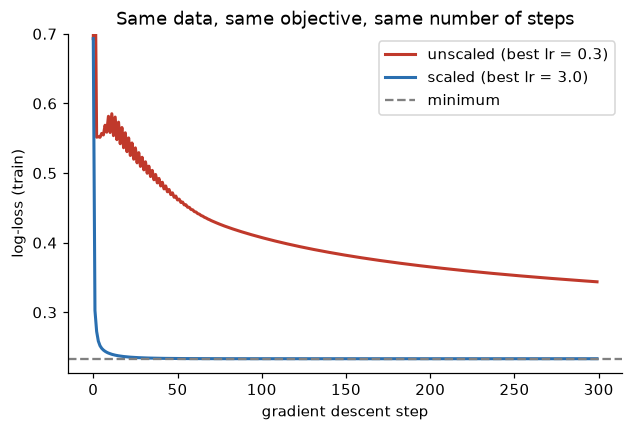

In [290]:
plt.figure(figsize=(6.5, 4))
for name, c in [("unscaled", "#c0392b"), ("scaled", "#2a6fb0")]:
    lr_b, curve = best[name]
    plt.plot(curve, color=c, lw=2, label=f"{name} (best lr = {lr_b})")
plt.axhline(optimum, color="gray", ls="--", label="minimum")
plt.xlabel("gradient descent step"); plt.ylabel("log-loss (train)"); plt.ylim(optimum - 0.02, 0.7)
plt.title("Same data, same objective, same number of steps"); plt.legend()
plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

> ### Checkpoint L4
> With unscaled features, gradient descent ended far above the minimum, even with its best learning rate. Why?
>
> **A)** hw_avg (0-10) has much bigger gradients than attendance (0-1): a step size small enough for hw_avg is far too small for attendance, and a bigger one makes hw_avg bounce  
> **B)** The unscaled data has more students  
> **C)** Log-loss is not defined for unscaled numbers  
> **D)** The sigmoid only works between -1 and 1  


In [291]:
check("L4", 'A')   # <- replace ? with your answer

[L4] Correct!
  Why: hw_avg (0-10) has much larger gradients than attendance (0-1). A learning rate small enough for hw_avg is far too small for attendance, and a larger one makes hw_avg bounce. Scaling makes the loss bowl round so one learning rate works for every feature.


**Takeaway:** scaling did not change the objective or its minimum - it changed the **shape** of the loss bowl from a long narrow valley into a round bowl, so one learning rate works for every direction.

*Small print:* `scikit-learn`'s `LogisticRegression` minimizes log-loss **plus a small penalty on large coefficients** (strength set by `C`, default 1). That is called regularization; it keeps coefficients from growing huge.

## Step 5 - Train logistic regression on all features

In [292]:
logit = LogisticRegression().fit(X_train, y_train)
print("intercept:", logit.intercept_.round(2), "  train log-loss:", round(log_loss(y_train, logit.predict_proba(X_train)), 4))
pd.Series(logit.coef_[0], index=FEATURES).round(2)

intercept: [1.88]   train log-loss: 0.2344


hw_avg                1.74
on_time_rate          0.60
midterm_attendance    0.86
final_attendance      0.97
exercises             0.50
section_B            -0.11
section_C             0.07
dtype: float64

## Step 6 - Probabilities and predictions
`predict_proba` gives P(pass); `predict` applies a **threshold of 0.5**.

In [293]:
p_pass = logit.predict_proba(X_test)[:, 1]
y_pred = logit.predict(X_test)
pd.DataFrame({"student_id": test["student_id"], "P(pass)": p_pass.round(3), "predicted": y_pred,
              "actual": y_test, "final_score": test["final_score"]}).head(8)

,student_id,P(pass),predicted,actual,final_score
0,S1306,0.958,1,1,78.4
1,S1065,0.981,1,1,83.1
2,S1138,1.000,1,1,92.1
3,S1041,0.003,0,0,42.9
4,S1002,0.984,1,1,80.5
5,S1069,0.663,1,1,76.2
6,S1121,0.768,1,1,80.7
7,S1343,0.491,0,1,72.8


## Step 7 - Evaluate
| | predicted fail | predicted pass |
|---|---|---|
| **actually fail** | true negative | false positive (a struggling student we missed!) |
| **actually pass** | false negative | true positive |

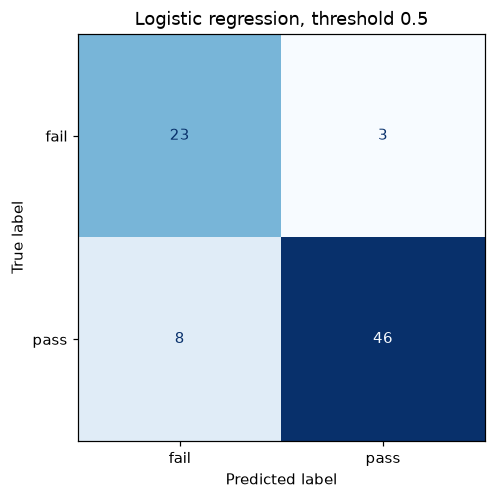

,accuracy,precision (pass),recall (pass),F1 (pass),fails found
everyone passes,0.675,0.675,1.0,0.80597,0 of 26
"logistic, t = 0.5",0.8625,0.938776,0.851852,0.893204,23 of 26


In [294]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["fail", "pass"]).plot(cmap="Blues", colorbar=False)
plt.title("Logistic regression, threshold 0.5"); plt.show()

def report(y_true, y_hat):
    return {"accuracy": accuracy_score(y_true, y_hat),
            "precision (pass)": precision_score(y_true, y_hat, zero_division=0),
            "recall (pass)": recall_score(y_true, y_hat),
            "F1 (pass)": f1_score(y_true, y_hat),
            "fails found": f"{((y_hat == 0) & (y_true == 0)).sum()} of {(y_true == 0).sum()}"}

pd.DataFrame({"everyone passes": report(y_test, baseline), "logistic, t = 0.5": report(y_test, y_pred)}).T

## Step 8 - Choosing the threshold: an early-warning system
Any student with P(pass) below a threshold gets an email and an office-hours invite. Missing a student who will fail is costly; emailing one who would pass anyway is cheap.

In [295]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flagged, fails = p_pass < t, (y_test == 0).values
    rows.append({"threshold": t, "students flagged": flagged.sum(),
                 "fails caught": (flagged & fails).sum(), "fails missed": (~flagged & fails).sum(),
                 "passers emailed anyway": (flagged & ~fails).sum(),
                 "accuracy": accuracy_score(y_test, (~flagged).astype(int))})
pd.DataFrame(rows).round(3)

,threshold,students flagged,fails caught,fails missed,passers emailed anyway,accuracy
0,0.3,22,20,6,2,0.900
1,0.4,25,20,6,5,0.862
2,0.5,31,23,3,8,0.862
3,0.6,33,25,1,8,0.888
4,0.7,36,26,0,10,0.875
5,0.8,40,26,0,14,0.825


**Think:** which threshold would you pick? Is the most accurate threshold the best one for this job?

> ### Checkpoint L5
> You move the threshold from 0.5 to 0.7. Does the model have to be retrained - do its coefficients change?
>
> **A)** Yes - a new threshold means a new objective, so fit() runs again  
> **B)** No - training minimized log-loss once; the threshold is a decision rule applied to the probabilities afterwards  
> **C)** Only the intercept changes  
> **D)** Only if the classes are balanced  


## Step 9 - ROC curve and AUC
AUC = chance that a random passing student gets a higher P(pass) than a random failing student (0.5 = coin flip, 1 = perfect).

In [296]:
check("L5", 'B')   # <- replace ? with your answer

[L5] Correct!
  Why: Training minimizes log-loss once and fixes the coefficients. The threshold is a decision rule applied to the probabilities afterwards, so changing it needs no retraining.


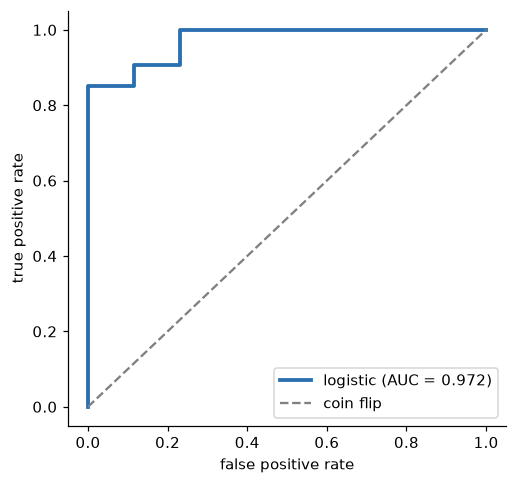

In [297]:
fpr, tpr, _ = roc_curve(y_test, p_pass)
auc = roc_auc_score(y_test, p_pass)
plt.figure(figsize=(4.8, 4.5))
plt.plot(fpr, tpr, color="#2a6fb0", lw=2.5, label=f"logistic (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="coin flip")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate"); plt.legend(loc="lower right")
plt.gca().spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## Step 10 - Coefficients as odds ratios
`exp(coefficient)` = how many times the **odds** of passing multiply when the feature goes up by one standard deviation.

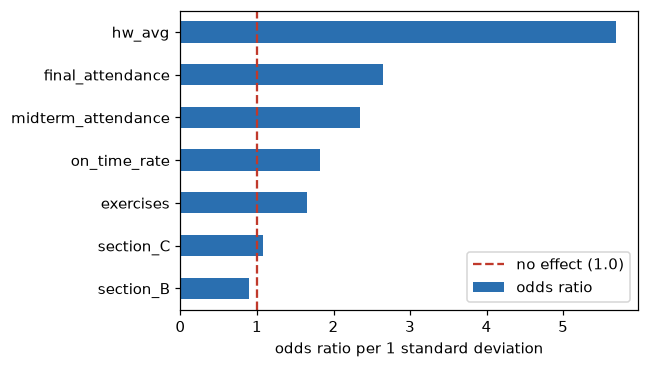

,coefficient,odds ratio
section_B,-0.11,0.89
section_C,0.07,1.08
exercises,0.50,1.66
on_time_rate,0.60,1.82
midterm_attendance,0.86,2.35
final_attendance,0.97,2.65
hw_avg,1.74,5.69


In [298]:
odds = pd.DataFrame({"coefficient": logit.coef_[0], "odds ratio": np.exp(logit.coef_[0])},
                    index=FEATURES).sort_values("odds ratio")
ax = odds["odds ratio"].plot.barh(figsize=(6, 0.35 * len(odds) + 1), color="#2a6fb0")
ax.axvline(1, color="#c0392b", ls="--", label="no effect (1.0)"); ax.legend()
ax.set_xlabel("odds ratio per 1 standard deviation"); plt.tight_layout(); plt.show()
odds.round(2)

## Step 11 - Logistic vs "linear regression, then cut at 70"

In [299]:
lin = joblib.load(DATA / "linear_model.joblib")
test_raw = pd.read_csv(DATA / "test_processed.csv")
lin_pass = (lin.predict(test_raw[FEATURES]) >= 70).astype(int)
pd.DataFrame({"linear score >= 70": report(y_test, lin_pass), "logistic, t = 0.5": report(y_test, y_pred)}).T

,accuracy,precision (pass),recall (pass),F1 (pass),fails found
linear score >= 70,0.875,0.958333,0.851852,0.901961,24 of 26
"logistic, t = 0.5",0.8625,0.938776,0.851852,0.893204,23 of 26


Often close. Linear regression gives a **score** (more information); logistic regression gives a **probability** (ready for ranking students by risk and choosing a threshold).

## Step 12 - Predict new students
New inputs must go through **the same scaler** fitted in notebook 01.

In [300]:
new_students = pd.DataFrame([
    {"hw_avg": 8.5, "on_time_rate": 1.00, "midterm_attendance": 0.95, "final_attendance": 0.90, "exercises": 1, "section_B": 0, "section_C": 0},
    {"hw_avg": 6.0, "on_time_rate": 0.50, "midterm_attendance": 0.80, "final_attendance": 0.60, "exercises": 0, "section_B": 0, "section_C": 1},
    {"hw_avg": 5.0, "on_time_rate": 0.33, "midterm_attendance": 0.70, "final_attendance": 0.55, "exercises": 0, "section_B": 1, "section_C": 0},
]).reindex(columns=FEATURES, fill_value=0)
model_input = new_students if scaler is None else pd.DataFrame(scaler.transform(new_students), columns=FEATURES)
new_students["P(pass)"] = logit.predict_proba(model_input)[:, 1].round(3)
new_students["predicted score (linear)"] = lin.predict(new_students[FEATURES]).round(1)
new_students

,hw_avg,on_time_rate,midterm_attendance,final_attendance,exercises,section_B,section_C,P(pass),predicted score (linear)
0,8.5,1.00,0.95,0.90,1,0,0,0.999,94.5
1,6.0,0.50,0.80,0.60,0,0,1,0.564,70.1
2,5.0,0.33,0.70,0.55,0,1,0,0.084,62.5


In [301]:
joblib.dump(logit, DATA / "logistic_model.joblib")
summary("L")

Correct: 6 / 6   L1 L2 L3 L4 L5 L6


## Recap: linear vs logistic regression
| | Linear regression | Logistic regression |
|---|---|---|
| Target | a number (final score) | a class (pass / fail) |
| Output | $\hat{y} = b_0 + b \cdot x$ | $p = \sigma(b_0 + b \cdot x)$, between 0 and 1 |
| **Objective minimized** | **mean squared error** | **log-loss** (cross-entropy) = maximum likelihood |
| Shape of the objective | convex bowl | convex bowl |
| How it is solved | exact formula (or gradient descent) | iterative optimizer / gradient descent |
| Does scaling change the answer? | no (same predictions) | only through regularization - but it makes the optimizer much faster |
| Metrics | MAE, RMSE, R² | confusion matrix, precision, recall, AUC |
| Coefficients | points per unit | log-odds; exp() = odds ratio |

## Your turn
1. In Step 8, pick a threshold and **justify it in two sentences** to the instructor.
- I Choose 0.7. Because it cathces all 26 failing students, misses none, and emails 10 students who would pass anyway. This has less risk since missing a failing student is more risky and has a bigger consequence. At 0.8, you send four more unnecessary emails
2. (opitional) In Step 4c, change `steps=300` to `steps=3000`. Does unscaled gradient descent ever reach the minimum? What does this cost in practice?
3. Change the pass mark to 60 in notebook 01 step 6 (`passed = final_score >= 60`) and rerun everything, you will need to run notebook 1 then run notebook3. What happens to the class balance, the baseline, and the fails found? and why?
- Lowering it to 60 increased the training pass rate to 85.6%, the everyone passes baseline increased from 67.5% to 85% accuracy because more students were set as passing. The logistic regression model caught 7 of 12 failing students instead of the previous 23 of 26. Although there were fewer failing students, the model caught a smaller ratio compared to the previous 70 model making it less accurate but more precise.
5. Student 2 in Step 12: which single change (more on-time homework, more attendance, or exercising) raises P(pass) the most?
- the single change that makes the largest raise to P is increasing the final attendence since increasing it to 1.00 increased P by .352
